In [2]:
!pip install ucimlrepo -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [3]:
data = fetch_ucirepo(id=603)
X = data.data.features.copy()
y = data.data.targets['Y'].copy()

df = pd.concat([X, y], axis=1)
print("Shape:", df.shape)
df.head()

Shape: (12684, 26)


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passenger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

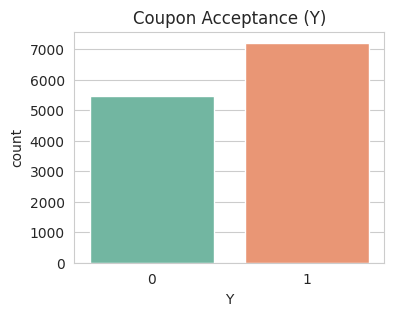

In [4]:
##data understanding

print(df.info())
print("\nTarget distribution:")
print(df['Y'].value_counts())
print((df['Y'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(4,3))
sns.countplot(x='Y', data=df, palette='Set2')
plt.title("Coupon Acceptance (Y)")
plt.show()

In [5]:
#Missing values

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(pd.DataFrame({'Missing': missing, 'Percent': (missing / len(df) * 100).round(2)}))

                      Missing  Percent
car                     12576    99.15
CoffeeHouse               217     1.71
Restaurant20To50          189     1.49
CarryAway                 151     1.19
RestaurantLessThan20      130     1.02
Bar                       107     0.84


In [6]:
#Preprocessing (missing values, drop ‘car’, mode imputation)

# 'car' is almost entirely missing (>99%), so drop it
df_clean = df.drop(columns=['car'], errors='ignore').copy()

# Duplicate check
print("Duplicates:", df_clean.duplicated().sum())

# Impute categorical columns with the mode
for col in df_clean.columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Remaining missing values:", df_clean.isnull().sum().sum())

X = df_clean.drop(columns='Y')
y = df_clean['Y']

# Identify column types
numeric_cols = ['temperature']                       # truly numeric (30, 55, 80)
cat_cols = [c for c in X.columns if c not in numeric_cols]
print("Categorical:", len(cat_cols), "| Numeric:", numeric_cols)

Duplicates: 74
Remaining missing values: 0
Categorical: 23 | Numeric: ['temperature']


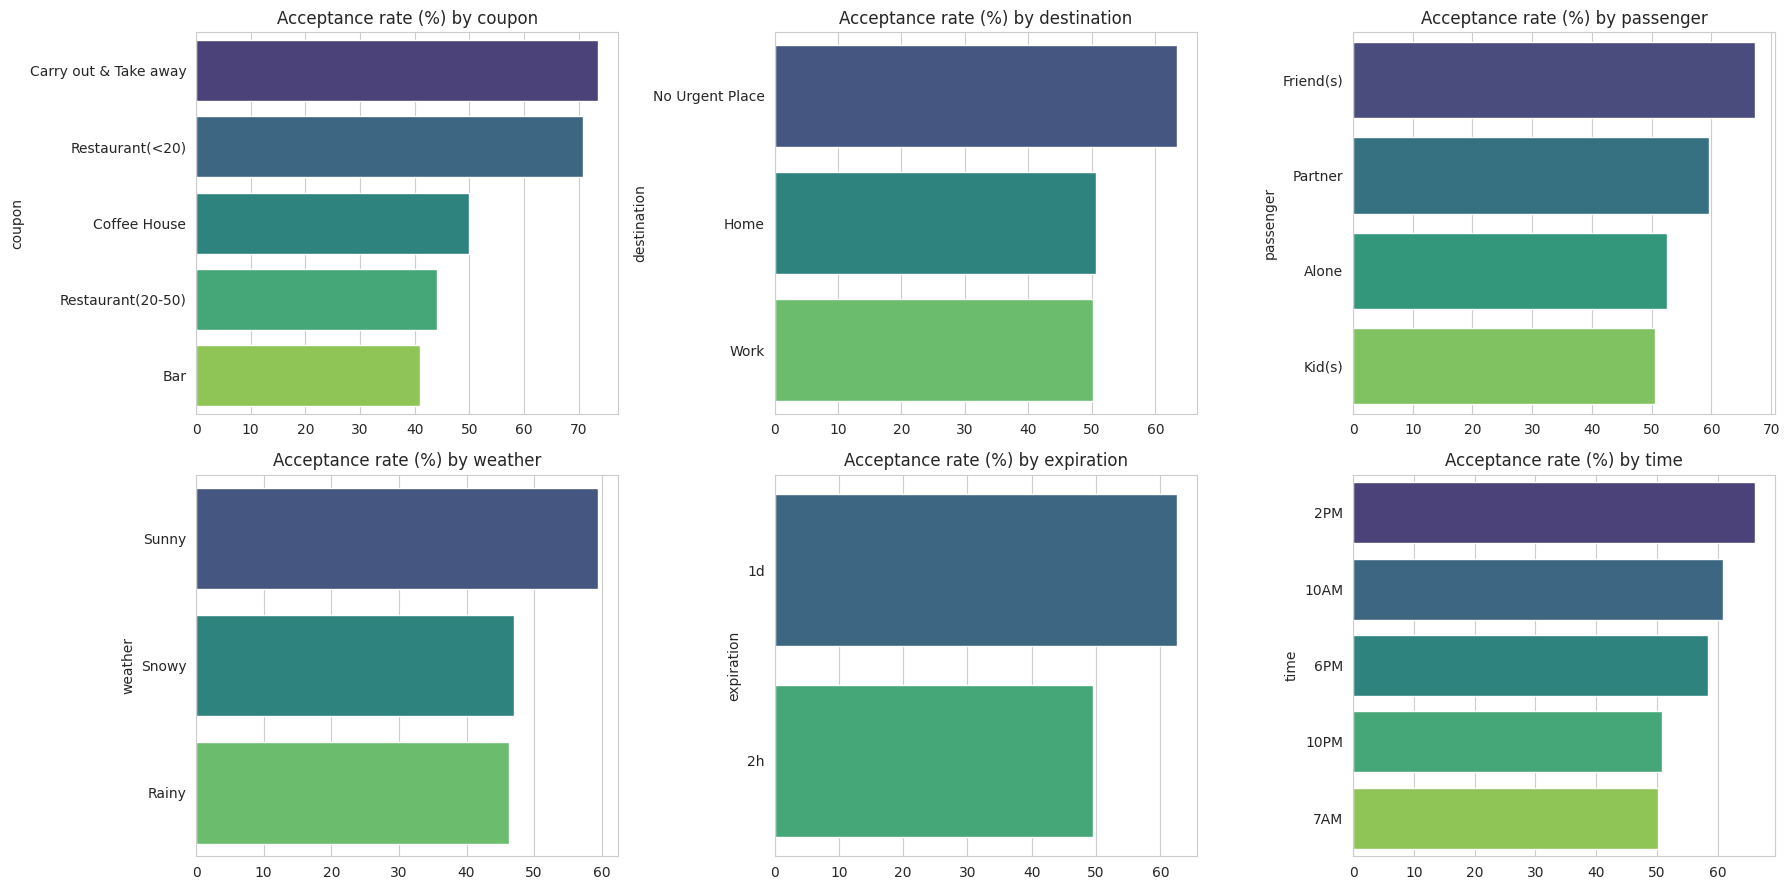

In [8]:
#Exploratory insights (acceptance rate by factor)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ['coupon', 'destination', 'passenger', 'weather', 'expiration', 'time']):
    rate = df_clean.groupby(col)['Y'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, palette='viridis')
    ax.set_title(f"Acceptance rate (%) by {col}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [9]:
#Train/test split and encoders

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Naive Bayes: ordinal encode all features (treated as categorical)
nb_pre = ColumnTransformer([
    ('ord', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols + numeric_cols)
])

# KNN: one-hot for categoricals + MinMax scaling for numeric (distance-based, so scaling matters)
knn_pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', MinMaxScaler(), numeric_cols)
])

In [10]:
# Naive Bayes model
# Encode the full feature set once so CategoricalNB knows all category counts
enc = OrdinalEncoder()
X_enc = pd.DataFrame(enc.fit_transform(X[cat_cols + numeric_cols]), columns=cat_cols + numeric_cols).astype(int)
Xe_train, Xe_test = X_enc.loc[X_train.index.map(X.index.get_loc)], X_enc.loc[X_test.index.map(X.index.get_loc)]

nb = CategoricalNB(alpha=1.0)
nb.fit(Xe_train, y_train)
y_pred_nb = nb.predict(Xe_test)
y_prob_nb = nb.predict_proba(Xe_test)[:, 1]

print("=== NAIVE BAYES ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_nb), 4))
print(classification_report(y_test, y_pred_nb, target_names=['Rejected (0)', 'Accepted (1)']))

=== NAIVE BAYES ===
Accuracy : 0.6539
              precision    recall  f1-score   support

Rejected (0)       0.61      0.54      0.57      1095
Accepted (1)       0.68      0.74      0.71      1442

    accuracy                           0.65      2537
   macro avg       0.65      0.64      0.64      2537
weighted avg       0.65      0.65      0.65      2537



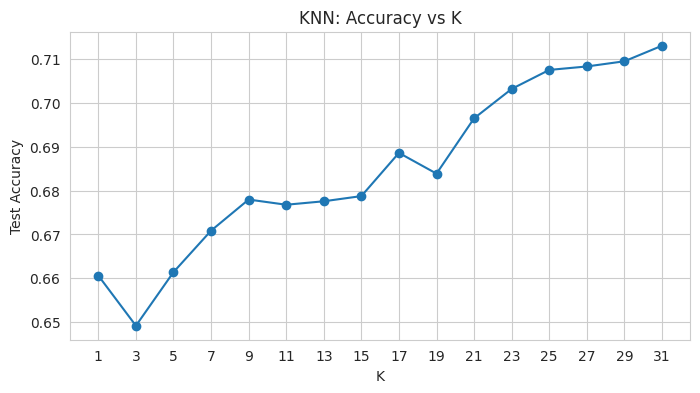

Best K: 31 | Accuracy: 0.713


In [11]:
# Find the best K for KNN

Xk_train = knn_pre.fit_transform(X_train)
Xk_test = knn_pre.transform(X_test)

k_values = range(1, 32, 2)
test_acc, cv_acc = [], []
skf = StratifiedKFold(5, shuffle=True, random_state=42)

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, metric='euclidean', n_jobs=-1)
    model.fit(Xk_train, y_train)
    test_acc.append(model.score(Xk_test, y_test))

plt.figure(figsize=(8,4))
plt.plot(list(k_values), test_acc, marker='o')
plt.xlabel("K"); plt.ylabel("Test Accuracy"); plt.title("KNN: Accuracy vs K")
plt.xticks(list(k_values)); plt.show()

best_k = list(k_values)[int(np.argmax(test_acc))]
print("Best K:", best_k, "| Accuracy:", round(max(test_acc), 4))

In [12]:
# KNN model

knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean', n_jobs=-1)
knn.fit(Xk_train, y_train)
y_pred_knn = knn.predict(Xk_test)
y_prob_knn = knn.predict_proba(Xk_test)[:, 1]

print(f"=== KNN (K={best_k}) ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_knn), 4))
print(classification_report(y_test, y_pred_knn, target_names=['Rejected (0)', 'Accepted (1)']))

=== KNN (K=31) ===
Accuracy : 0.713
              precision    recall  f1-score   support

Rejected (0)       0.73      0.54      0.62      1095
Accepted (1)       0.71      0.85      0.77      1442

    accuracy                           0.71      2537
   macro avg       0.72      0.69      0.69      2537
weighted avg       0.72      0.71      0.70      2537



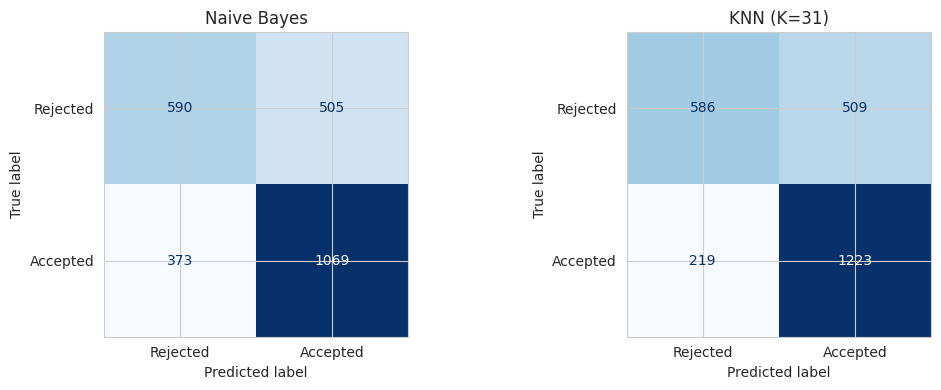

In [13]:
# Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [y_pred_nb, y_pred_knn], ['Naive Bayes', f'KNN (K={best_k})']):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Rejected', 'Accepted']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

,Accuracy,Precision,Recall,F-measure,ROC-AUC
Naive Bayes,0.6539,0.6792,0.7413,0.7089,0.7013
KNN (K=31),0.7130,0.7061,0.8481,0.7706,0.7656


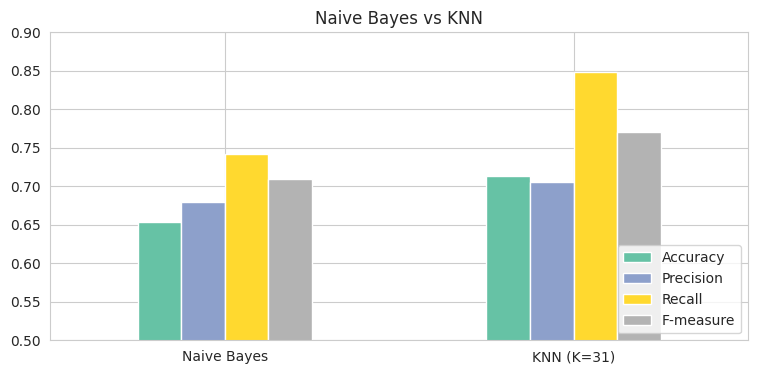

Better algorithm (by F-measure): KNN (K=31)


In [14]:
# Comparison table and chart

def metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F-measure': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame({
    'Naive Bayes': metrics(y_test, y_pred_nb, y_prob_nb),
    f'KNN (K={best_k})': metrics(y_test, y_pred_knn, y_prob_knn)
}).T.round(4)

display(results)
results.drop(columns='ROC-AUC').plot(kind='bar', figsize=(9,4), rot=0, colormap='Set2')
plt.title("Naive Bayes vs KNN"); plt.ylim(0.5, 0.9); plt.legend(loc='lower right'); plt.show()

print("Better algorithm (by F-measure):", results['F-measure'].idxmax())

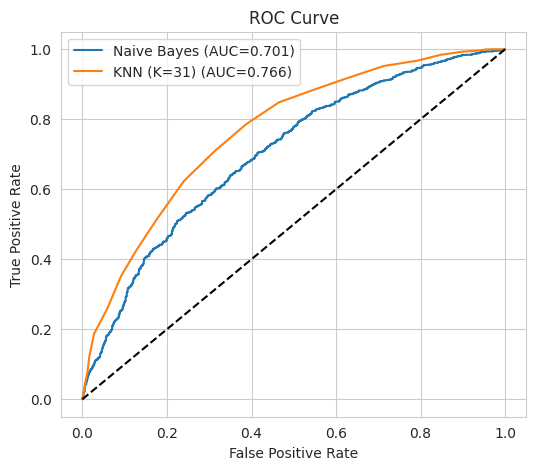

In [15]:
# ROC curves

plt.figure(figsize=(6,5))
for prob, name in [(y_prob_nb, 'Naive Bayes'), (y_prob_knn, f'KNN (K={best_k})')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.show()

In [16]:
# 10-fold cross-validation (same as WEKA’s default)

skf10 = StratifiedKFold(10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1']

nb_pipe = Pipeline([('enc', OrdinalEncoder()), ('clf', CategoricalNB(alpha=1.0, min_categories=X_enc.max().values + 1))])
knn_pipe = Pipeline([('pre', knn_pre), ('clf', KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1))])

cv_rows = {}
for name, pipe, Xin in [('Naive Bayes', nb_pipe, X[cat_cols + numeric_cols]),
                        (f'KNN (K={best_k})', knn_pipe, X)]:
    cv = cross_validate(pipe, Xin, y, cv=skf10, scoring=scoring)
    cv_rows[name] = {m: cv[f'test_{m}'].mean() for m in scoring}

cv_df = pd.DataFrame(cv_rows).T.round(4)
cv_df.columns = ['Accuracy', 'Precision', 'Recall', 'F-measure']
display(cv_df)

,Accuracy,Precision,Recall,F-measure
Naive Bayes,0.6637,0.6905,0.7406,0.7146
KNN (K=31),0.7129,0.7103,0.8359,0.7680


In [18]:
# ---------- Part A: Predictions on the test set (actual vs predicted) ----------
pred_df = X_test.copy()
pred_df['Actual'] = y_test.values
pred_df['NaiveBayes_Pred'] = y_pred_nb
pred_df['NaiveBayes_Prob_Accept'] = y_prob_nb.round(3)
pred_df['KNN_Pred'] = y_pred_knn
pred_df['KNN_Prob_Accept'] = y_prob_knn.round(3)

label = {0: 'Rejected', 1: 'Accepted'}
print("Sample of test set predictions:")
display(pred_df[['coupon', 'destination', 'passenger', 'weather', 'time', 'age',
                 'Actual', 'NaiveBayes_Pred', 'NaiveBayes_Prob_Accept',
                 'KNN_Pred', 'KNN_Prob_Accept']].head(10))

print("\nBoth models agree on", (pred_df['NaiveBayes_Pred'] == pred_df['KNN_Pred']).mean().round(3) * 100, "% of test cases")


# ---------- Part B: Predict for a NEW customer scenario ----------
def predict_coupon(**overrides):
    """Start from the most typical scenario (mode of every column), override what you specify."""
    sample = X.mode().iloc[[0]].copy()
    for col, val in overrides.items():
        sample[col] = val
    sample = sample[X.columns]

    # Naive Bayes input (ordinal encoded)
    s_nb = pd.DataFrame(enc.transform(sample[cat_cols + numeric_cols]),
                        columns=cat_cols + numeric_cols).astype(int)
    nb_pred = nb.predict(s_nb)[0]
    nb_prob = nb.predict_proba(s_nb)[0][1]

    # KNN input (one-hot + scaled)
    s_knn = knn_pre.transform(sample)
    knn_pred = knn.predict(s_knn)[0]
    knn_prob = knn.predict_proba(s_knn)[0][1]

    return pd.Series({
        'Naive Bayes': f"{label[nb_pred]} (P(accept)={nb_prob:.2f})",
        f'KNN (K={best_k})': f"{label[knn_pred]} (P(accept)={knn_prob:.2f})"
    })

# Try different scenarios (change the values as you like)
scenarios = {
    "Coffee House, friends, sunny, 2PM, 80F": dict(coupon='Coffee House', passenger='Friend(s)',
                                                  weather='Sunny', time='2PM', temperature=80),
    "Bar coupon, alone, rainy, 10PM, 55F":    dict(coupon='Bar', passenger='Alone',
                                                  weather='Rainy', time='10PM', temperature=55),
    "Cheap restaurant, partner, 6PM, 2h expiry": dict(coupon='Restaurant(<20)', passenger='Partner',
                                                     time='6PM', expiration='2h'),
    "Carry out, going home, 1-day expiry":    dict(coupon='Carry out & Take away', destination='Home',
                                                  expiration='1d'),
}

results_new = pd.DataFrame({name: predict_coupon(**params) for name, params in scenarios.items()}).T
display(results_new)

# See all valid values for any column before writing your own scenario:
# print(X['coupon'].unique()); print(X['passenger'].unique()); print(X['time'].unique())

Sample of test set predictions:


,coupon,destination,passenger,weather,time,age,Actual,NaiveBayes_Pred,NaiveBayes_Prob_Accept,KNN_Pred,KNN_Prob_Accept
11547,Restaurant(20-50),No Urgent Place,Kid(s),Sunny,10PM,31,0,0,0.457,0,0.387
6584,Coffee House,No Urgent Place,Alone,Sunny,6PM,36,0,0,0.324,0,0.387
780,Coffee House,Home,Alone,Sunny,6PM,26,1,1,0.683,1,0.742
8135,Coffee House,No Urgent Place,Alone,Sunny,10AM,31,0,1,0.753,0,0.484
1303,Restaurant(<20),No Urgent Place,Alone,Sunny,2PM,21,1,1,0.908,1,0.710
673,Restaurant(20-50),Work,Alone,Sunny,7AM,31,1,1,0.524,1,0.548
543,Restaurant(<20),Work,Alone,Sunny,7AM,50plus,1,1,0.651,1,0.742
12677,Restaurant(<20),Home,Partner,Sunny,6PM,26,1,1,0.501,0,0.323
3434,Coffee House,No Urgent Place,Friend(s),Sunny,6PM,26,1,1,0.884,1,0.742
11700,Restaurant(20-50),Home,Kid(s),Sunny,10PM,50plus,0,0,0.204,0,0.387



Both models agree on 74.5 % of test cases


,Naive Bayes,KNN (K=31)
"Coffee House, friends, sunny, 2PM, 80F",Accepted (P(accept)=0.80),Accepted (P(accept)=0.55)
"Bar coupon, alone, rainy, 10PM, 55F",Rejected (P(accept)=0.27),Rejected (P(accept)=0.32)
"Cheap restaurant, partner, 6PM, 2h expiry",Accepted (P(accept)=0.74),Accepted (P(accept)=0.68)
"Carry out, going home, 1-day expiry",Accepted (P(accept)=0.73),Accepted (P(accept)=0.52)


In [25]:
!pip install streamlit -q

import joblib, os
os.makedirs("app_files", exist_ok=True)

# Dropdown options for every feature (values exactly as seen in training)
options = {c: sorted(X[c].unique().tolist(), key=str) for c in X.columns}

artifacts = {
    "nb": nb, "enc": enc,                 # Naive Bayes + its encoder
    "knn": knn, "knn_pre": knn_pre,       # KNN + its one-hot/scaler pipeline
    "best_k": best_k,
    "cat_cols": cat_cols, "numeric_cols": numeric_cols,
    "columns": list(X.columns),
    "defaults": X.mode().iloc[0].to_dict(),
    "options": options,
    "results": results,                   # comparison table from Cell 12
    "cv_results": cv_df,                  # 10-fold CV table from Cell 14
}
joblib.dump(artifacts, "app_files/artifacts.pkl")
df_clean.to_csv("app_files/clean_data.csv", index=False)
print("Saved:", os.listdir("app_files"))

Saved: ['clean_data.csv', 'artifacts.pkl']


In [26]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Smart Coupon Acceptance", page_icon="🎟️", layout="wide")

@st.cache_resource
def load():
    return joblib.load("app_files/artifacts.pkl")

@st.cache_data
def load_data():
    return pd.read_csv("app_files/clean_data.csv")

A = load()
df = load_data()
opts, defaults = A["options"], A["defaults"]
label = {0: "Rejected ❌", 1: "Accepted ✅"}

st.title("🎟️ Smart Coupon Acceptance Analysis")
st.caption("Naive Bayes vs K-Nearest Neighbors | UCI In-Vehicle Coupon Recommendation Dataset")

tab1, tab2, tab3 = st.tabs(["🔮 Predict", "📊 Model Comparison", "💡 Business Insights"])

# ---------------- TAB 1: PREDICT ----------------
with tab1:
    st.subheader("Describe the customer and coupon scenario")

    main_cols = ["coupon", "destination", "passenger", "weather",
                 "temperature", "time", "expiration"]
    cust_cols = ["age", "gender", "maritalStatus", "income", "occupation", "education"]

    def pick(col, container):
        vals = opts[col]
        idx = vals.index(defaults[col]) if defaults[col] in vals else 0
        return container.selectbox(col, vals, index=idx, key=col)

    inputs = {}
    st.markdown("**Coupon & travel situation**")
    c = st.columns(4)
    for i, col in enumerate(main_cols):
        inputs[col] = pick(col, c[i % 4])

    st.markdown("**Customer details**")
    c = st.columns(3)
    for i, col in enumerate(cust_cols):
        inputs[col] = pick(col, c[i % 3])

    remaining = [x for x in A["columns"] if x not in inputs]
    with st.expander("Advanced: customer habits & other attributes (defaults to most common)"):
        c = st.columns(3)
        for i, col in enumerate(remaining):
            inputs[col] = pick(col, c[i % 3])

    if st.button("Predict coupon acceptance", type="primary"):
        sample = pd.DataFrame([inputs])[A["columns"]]

        # Naive Bayes
        s_nb = pd.DataFrame(A["enc"].transform(sample[A["cat_cols"] + A["numeric_cols"]]),
                            columns=A["cat_cols"] + A["numeric_cols"]).astype(int)
        nb_pred = int(A["nb"].predict(s_nb)[0])
        nb_prob = float(A["nb"].predict_proba(s_nb)[0][1])

        # KNN
        s_knn = A["knn_pre"].transform(sample)
        knn_pred = int(A["knn"].predict(s_knn)[0])
        knn_prob = float(A["knn"].predict_proba(s_knn)[0][1])

        col1, col2 = st.columns(2)
        with col1:
            st.markdown("### Naive Bayes")
            st.metric("Prediction", label[nb_pred])
            st.progress(nb_prob, text=f"P(accept) = {nb_prob:.1%}")
        with col2:
            st.markdown(f"### KNN (K={A['best_k']})")
            st.metric("Prediction", label[knn_pred])
            st.progress(knn_prob, text=f"P(accept) = {knn_prob:.1%}")

        avg = (nb_prob + knn_prob) / 2
        if nb_pred == knn_pred:
            st.success(f"Both models agree: **{label[nb_pred]}** (average P(accept) = {avg:.1%})")
        else:
            st.warning(f"Models disagree. Average P(accept) = {avg:.1%}. Treat this case as uncertain.")

# ---------------- TAB 2: MODEL COMPARISON ----------------
with tab2:
    st.subheader("Hold-out test results (80/20 split)")
    st.dataframe(A["results"].style.highlight_max(axis=0, color="#c6efce"), use_container_width=True)
    st.bar_chart(A["results"].drop(columns="ROC-AUC"))

    st.subheader("10-fold cross-validation results")
    st.dataframe(A["cv_results"].style.highlight_max(axis=0, color="#c6efce"), use_container_width=True)

    best = A["results"]["F-measure"].idxmax()
    st.info(f"Better algorithm by F-measure on the test set: **{best}**")

# ---------------- TAB 3: BUSINESS INSIGHTS ----------------
with tab3:
    st.subheader("Acceptance rate by factor")
    factor = st.selectbox("Choose a factor",
                          ["coupon", "destination", "passenger", "weather", "time",
                           "expiration", "age", "income", "occupation", "maritalStatus"])
    rate = (df.groupby(factor)["Y"].mean() * 100).sort_values(ascending=False).round(1)
    st.bar_chart(rate)
    st.dataframe(rate.rename("Acceptance rate (%)"), use_container_width=True)
    st.caption(f"Overall acceptance rate: {df['Y'].mean()*100:.1f}%")

Overwriting app.py


In [27]:
import subprocess, time, re, os

# Download cloudflared (free tunnel, no account needed)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

# Stop any earlier runs
!pkill -f streamlit
!pkill -f cloudflared

# Start Streamlit in the background
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501",
                  "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(5)

# Start the tunnel and read the public URL from its log
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url = None
start = time.time()
while time.time() - start < 40:
    line = tunnel.stdout.readline()
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        url = m.group(0)
        break

print("🚀 Open your app here:", url)

🚀 Open your app here: https://glucose-hansen-describing-operating.trycloudflare.com


In [24]:
!pkill -f streamlit
!pkill -f cloudflared
print("Streamlit and tunnel stopped")

Streamlit and tunnel stopped
